In [1]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict
from langchain_google_genai import ChatGoogleGenerativeAI
from dotenv import load_dotenv
import os


In [2]:
load_dotenv()

model = ChatGoogleGenerativeAI(
    model="gemini-3.6-flash",
    api_key=os.getenv("API_KEY"),
    temperature=0)


#creating state class for managing state for graph
class BlogState(TypedDict):
    title: str
    outline: str
    content: str

In [3]:
def llm_generate_outline(state: BlogState) -> BlogState:
    title = state.get("title", "")
    prompt = f"Generate a detailed outline for a blog post titled: '{title}'. Keep it with 2 topics and 2 subtopics for each topic.'"
    response = model.invoke(prompt).text
    state["outline"] = response
    return state

In [4]:
def llm_create_blog_post  (state: BlogState) -> BlogState:
    outline = state.get("outline", "")
    title = state.get("title", "")
    prompt = f"Write a blog post based on the title: '{title}' using following outline:\n{outline}. Make sure to keep explanations between 10 to 20 words each for outline topics and subtopics. The blog post should be in a conversational tone and engaging for readers."
    response = model.invoke(prompt).text
    state["content"] = response
    return state 

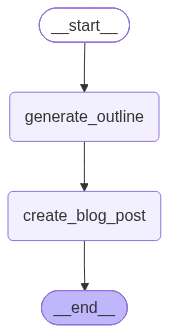

In [5]:
# Create graph
graph= StateGraph(BlogState)

#creating node
graph.add_node("generate_outline", llm_generate_outline)
graph.add_node("create_blog_post", llm_create_blog_post)

#creating edges
graph.add_edge(START, "generate_outline")
graph.add_edge("generate_outline", "create_blog_post")
graph.add_edge("create_blog_post", END)

#compile graph
workflow = graph.compile()

workflow

In [6]:
#call graph
initial_state = {"title": "The Future of AI in Healthcare"}
final_output = workflow.invoke(initial_state)
print(final_output)

d:\Tutorials\SimpleChatBot\venv\Lib\site-packages\langchain_google_genai\chat_models.py:3919: UserWarning: Model 'gemini-3.6-flash' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
d:\Tutorials\SimpleChatBot\venv\Lib\site-packages\langchain_google_genai\chat_models.py:3919: UserWarning: Model 'gemini-3.6-flash' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


{'title': 'The Future of AI in Healthcare', 'outline': 'Here is a detailed outline for the blog post **"The Future of AI in Healthcare"**, structured with exactly two main topics and two subtopics under each.\n\n---\n\n# **Blog Post Outline: The Future of AI in Healthcare**\n\n## **Introduction**\n* **Hook:** Highlight how artificial intelligence is moving from a futuristic concept to an essential backbone of modern medicine.\n* **Thesis Statement:** As AI continues to evolve, its most profound impacts will be seen in revolutionary diagnostic precision and the radical overhaul of healthcare delivery systems.\n\n---\n\n## **Topic 1: Next-Generation Precision Medicine and Early Diagnostics**\n*Focuses on how AI is elevating clinical outcomes through ultra-personalized patient care and proactive disease detection.*\n\n### **Subtopic 1.1: Predictive Analytics and Early Disease Detection**\n* **Key Focus:** Shifting healthcare from reactive treatment to proactive prevention.\n* **Detailed P

In [7]:
print(final_output.get("outline", "No outline generated."))

Here is a detailed outline for the blog post **"The Future of AI in Healthcare"**, structured with exactly two main topics and two subtopics under each.

---

# **Blog Post Outline: The Future of AI in Healthcare**

## **Introduction**
* **Hook:** Highlight how artificial intelligence is moving from a futuristic concept to an essential backbone of modern medicine.
* **Thesis Statement:** As AI continues to evolve, its most profound impacts will be seen in revolutionary diagnostic precision and the radical overhaul of healthcare delivery systems.

---

## **Topic 1: Next-Generation Precision Medicine and Early Diagnostics**
*Focuses on how AI is elevating clinical outcomes through ultra-personalized patient care and proactive disease detection.*

### **Subtopic 1.1: Predictive Analytics and Early Disease Detection**
* **Key Focus:** Shifting healthcare from reactive treatment to proactive prevention.
* **Detailed Points:**
  * **Pattern Recognition:** Using deep learning algorithms to a

In [8]:
print(final_output.get("content", "No content generated."))

# The Future of AI in Healthcare

Not too long ago, artificial intelligence in medicine sounded like a plot point from a sci-fi movie. Today, it is rapidly transforming into the indispensable backbone of modern medical care. From hospital wards to local neighborhood clinics, intelligent algorithms are changing how doctors diagnose, treat, and connect with patients. As AI continues to evolve, its most profound impacts will be seen in revolutionary diagnostic precision and the radical overhaul of healthcare delivery systems.

---

## Topic 1: Next-Generation Precision Medicine and Early Diagnostics
*Topic 1 focuses on leveraging advanced artificial intelligence to deliver hyper-personalized treatments and detect diseases before symptoms appear.*

### Subtopic 1.1: Predictive Analytics and Early Disease Detection
*Predictive analytics transforms modern healthcare by shifting clinical focus from treating active illnesses to preventing them entirely.*

Imagine catching a life-threatening il